# Análise da diferença de imagens

### Neste exercício utilizaremos o conjunto de dados da FEI + duas fotos inéditas
- Faça o download do conjunto de dados: https://fei.edu.br/~cet/frontalimages_manuallyaligned_part1.zip
- Descompacte o conjunto e dados no mesmo diretório deste arquivo
- Copie as duas imagens inéditas para o mesmo diretório deste arquivo

##### Passo 1: Importar as bibliotecas necessárias

In [19]:
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob

##### Passo 2: Importar o conjunto de dados da FEI

In [20]:
# Criando uma variável para armazenar as imagens
dataset = []

# Criando um laço de repetição para importar cada imagem
for file in glob.glob("frontalimages_manuallyaligned_part1/*.jpg"):
    # Carredando a imagem do índice
    load_file = Image.open(file)
    # Convertendo a imagem e tons de cinza
    load_file = load_file.convert("L")
    # Convertendo o objeto imagem em array
    load_file = np.array(load_file)
    # Adicionando a array da na variável dataset
    dataset.append(load_file)
# Convertendo a lista de imagens em array
dataset = np.array(dataset)

In [21]:
# Dimensão do conjunto de dados
dataset.shape

(200, 360, 260)

##### Passo 3: Importar as duas fotos inéditas

In [22]:
foto_neutra = np.array(Image.open('./minha_foto_a.jpg').convert("L"))
foto_sorrindo = np.array(Image.open('./minha_foto_b.jpg').convert("L"))

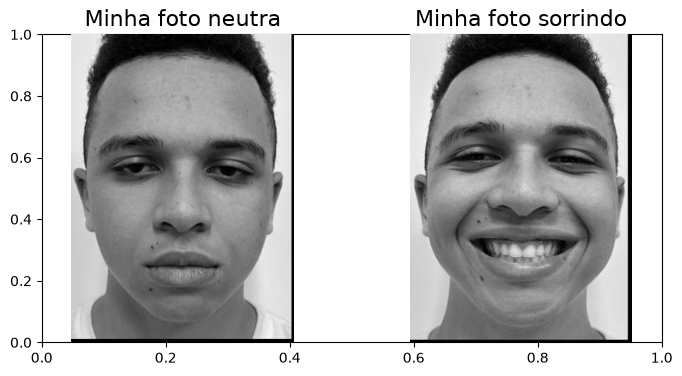

 Dimensões da foto neutra: (360, 260)
Dimensões da foto sorrindo: (360, 260)


In [23]:
# Visualizando as fotos inéditas

# Configurando o tamanho da área de visualização
plt.subplots(figsize=(8, 4))

# Configurando a visualização da imagem neutra 
plt.subplot(1,2,1)
plt.imshow(foto_neutra, cmap='gray')
plt.title('Minha foto neutra', fontsize=16)
plt.axis('off')

# Configurando a visualização da imagem sorrindo 
plt.subplot(1,2,2)
plt.imshow(foto_sorrindo, cmap='gray')
plt.title('Minha foto sorrindo', fontsize=16)
plt.axis('off')

plt.show()

# Imprime as dimensões das imagens
print(' Dimensões da foto neutra:', foto_neutra.shape)
print('Dimensões da foto sorrindo:', foto_sorrindo.shape)

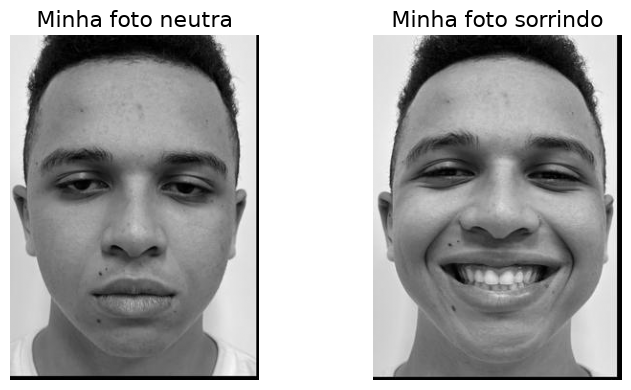

In [24]:
# Cria a figura e os 2 espaços lado a lado diretamente
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

# Configurando a imagem neutra
axes[0].imshow(foto_neutra, cmap='gray')
axes[0].set_title('Minha foto neutra', fontsize=16)
axes[0].axis('off')

# Configurando a imagem sorrindo
axes[1].imshow(foto_sorrindo, cmap='gray')
axes[1].set_title('Minha foto sorrindo', fontsize=16)
axes[1].axis('off')

plt.tight_layout()
plt.show()


##### Passo 4: Calcular a diferença das fotos inéditas em relação ao conjunto de dados da FEI

In [25]:

# Obtendo a dimensão do conjunto de imagens
indice = dataset.shape[0]

# Criando variáveis para armazenar a diferença das imagens
dif_neutral = np.zeros([indice])
dif_smiling = np.zeros([indice])

# Criando um laço de repetição para calcular a diferença entre as imagens
for img in range(indice):
    dif_neutral[img] = np.sum(abs(dataset[img,:,:]-foto_neutra))
    dif_smiling[img] = np.sum(abs(dataset[img,:,:]-foto_sorrindo))


In [26]:
df_dif_neutral = pd.DataFrame(dif_neutral, columns = ['Diferença'] )
df_dif_neutral

,Diferença
0,15184570.0
1,14866601.0
2,14978560.0
3,14907688.0
4,13343321.0
...,...
195,13986972.0
196,13156011.0
197,13659011.0
198,14814572.0


In [27]:
s_dif_neutral = df_dif_neutral.sort_values(by = 'Diferença').head(5)
s_dif_neutral

,Diferença
61,13141791.0
60,13146235.0
40,13151973.0
196,13156011.0
41,13185396.0


In [28]:
# Obtendo o índice das imagens com menor diferença da imagem neutra
id_neutral = list(s_dif_neutral.index)
id_neutral

[61, 60, 40, 196, 41]

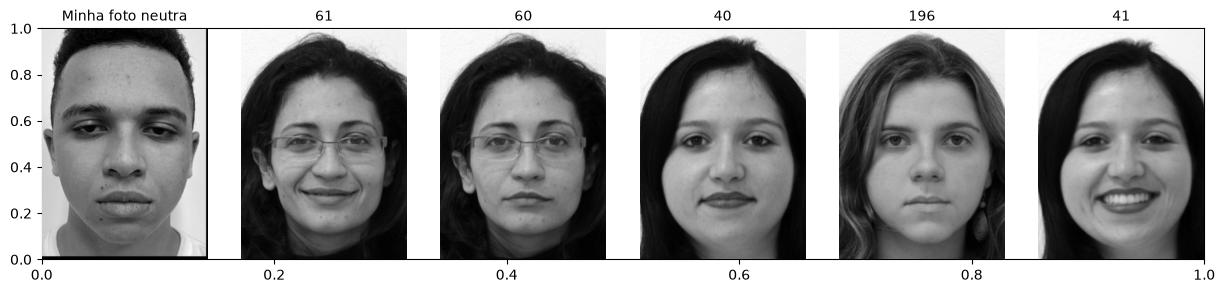

In [30]:
# Visualizando as imagens com menor diferença

# Configurando o tamanho da área de visualização
plt.subplots(figsize=(15, 3))

# Configurando a visualização da minha imagem neutra 
plt.subplot(1,len(id_neutral)+1,1)
plt.imshow(foto_neutra, cmap='gray')
plt.title('Minha foto neutra', fontsize=10)
plt.axis('off')

position = 2
for id_img in id_neutral:
    # Configurando a visualização da imagem média neutra 
    plt.subplot(1,len(id_neutral)+1,position)
    position += 1
    plt.imshow(dataset[id_img,:,:], cmap='gray')
    plt.title(id_img, fontsize=10)
    plt.axis('off')

plt.show()

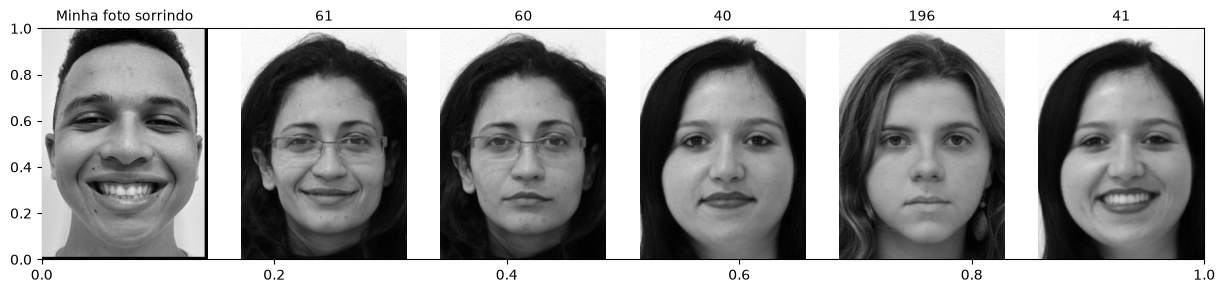

In [31]:
# Visualizando as imagens com menor diferença

# Configurando o tamanho da área de visualização
plt.subplots(figsize=(15, 3))

# Configurando a visualização da minha imagem neutra 
plt.subplot(1,len(id_neutral)+1,1)
plt.imshow(foto_sorrindo, cmap='gray')
plt.title('Minha foto sorrindo', fontsize=10)
plt.axis('off')

position = 2
for id_img in id_neutral:
    # Configurando a visualização da imagem média neutra 
    plt.subplot(1,len(id_neutral)+1,position)
    position += 1
    plt.imshow(dataset[id_img,:,:], cmap='gray')
    plt.title(id_img, fontsize=10)
    plt.axis('off')

plt.show()

#### Repetindo o processo para foto sorrindo...